# CAMD Screening Analysis

This notebook analyzes CAMD screening logs to visualize rejection reasons at different screening stages.

In [1]:
import re
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from collections import defaultdict

## Configuration

Set the path to your CAMD log file here:

In [2]:
# Define log file path
log_file = '../results/design/camd_run_20260107_000549.log'

## Parse Rejection Reasons

In [3]:
def parse_rejection_reasons(log_path):
    """
    Parse CAMD log file to extract rejection reasons.
    
    Returns:
        tuple: (pure_rejections, mixture_rejections) dictionaries with counts
    """
    with open(log_path, 'r') as f:
        content = f.read()
    
    pure_rejections = defaultdict(int)
    mixture_rejections = defaultdict(int)
    
    # Parse Step 9: Pure Property Rejections
    pure_section = re.search(
        r'STEP 9: Screen Pure Properties.*?Rejection reasons:(.*?)(?=Summary:|STEP 10:)',
        content, re.DOTALL
    )
    
    if pure_section:
        rejection_text = pure_section.group(1)
        
        # Count rejections by property
        for line in rejection_text.strip().split('\n'):
            line = line.strip()
            if not line or line.startswith('solvent_'):
                if 'tb=' in line.lower() and 'outside' in line.lower():
                    pure_rejections['$T_b$'] += 1
                elif 'tm=' in line.lower() and 'outside' in line.lower():
                    pure_rejections['$T_m$'] += 1
                elif 'tc=' in line.lower() and 'outside' in line.lower():
                    pure_rejections['$T_c$'] += 1
                elif 'pc=' in line.lower() and 'outside' in line.lower():
                    pure_rejections['$P_c$'] += 1
                elif 'hv=' in line.lower() and 'outside' in line.lower():
                    pure_rejections['$\\Delta H_{vap}$'] += 1
                elif 'tb (' in line.lower() and '>= tc' in line.lower():
                    pure_rejections['$T_b \\geq T_c$'] += 1
    
    # Parse Step 13: Mixture Property Rejections
    mixture_section = re.search(
        r'STEP 13: Screen Mixture Properties.*?Rejection reasons:(.*?)(?=Summary:|STEP 14:)',
        content, re.DOTALL
    )
    
    if mixture_section:
        rejection_text = mixture_section.group(1)
        
        # Count rejections by property
        for line in rejection_text.strip().split('\n'):
            line = line.strip()
            if not line or line.startswith('solvent_'):
                if 'azeotrope' in line.lower():
                    mixture_rejections['Azeotrope'] += 1
                elif 'phase split' in line.lower() or 'instability' in line.lower():
                    mixture_rejections['Miscibility'] += 1
                elif 'low selectivity' in line.lower() or 'selectivity' in line.lower():
                    mixture_rejections['Selectivity'] += 1
    
    return pure_rejections, mixture_rejections


# Parse the log file
pure_rejections, mixture_rejections = parse_rejection_reasons(log_file)

print("Pure Property Rejections:")
for prop, count in sorted(pure_rejections.items(), key=lambda x: x[1], reverse=True):
    print(f"  {prop:20s}: {count:4d}")

print("\nMixture Property Rejections:")
for prop, count in sorted(mixture_rejections.items(), key=lambda x: x[1], reverse=True):
    print(f"  {prop:20s}: {count:4d}")

Pure Property Rejections:
  $T_b$               :   80
  $\Delta H_{vap}$    :   51
  $T_m$               :    5
  $T_b \geq T_c$      :    1

Mixture Property Rejections:
  Selectivity         :  312
  Azeotrope           :   11


## Create Publication-Quality Bar Plot


Figure saved as:
  - rejection_reasons.pdf (for LaTeX)
  - rejection_reasons.png (for presentations)


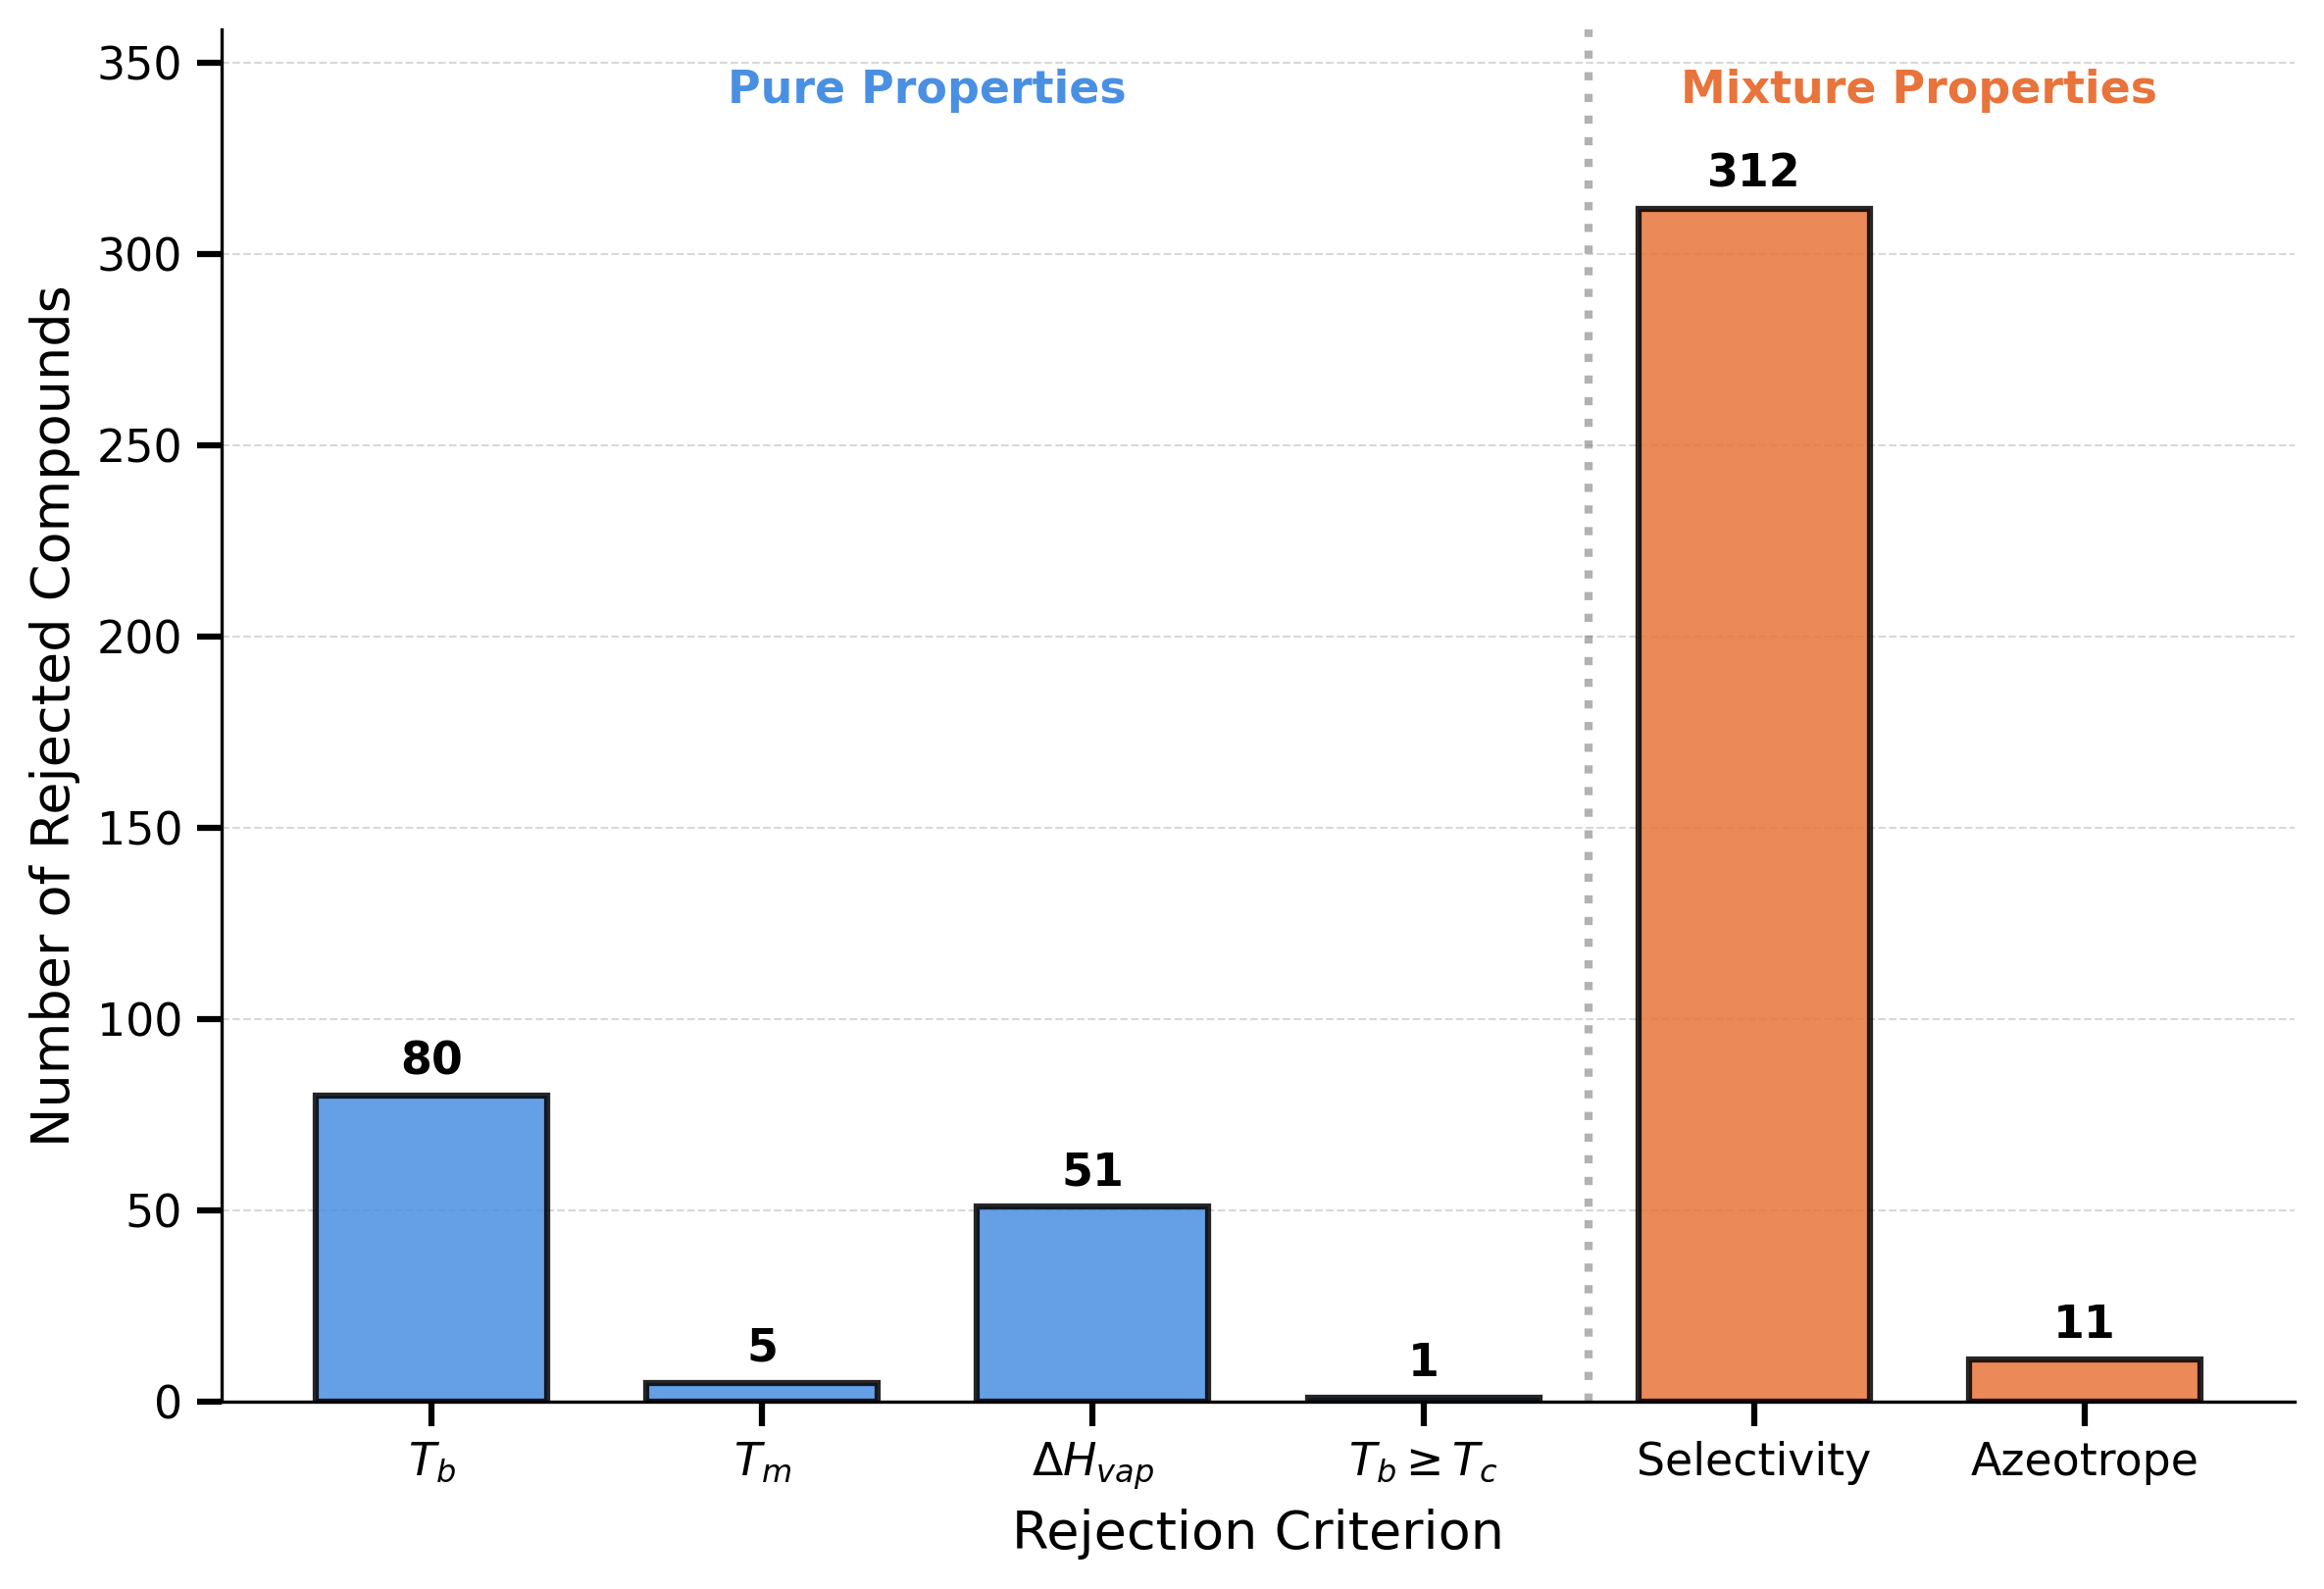

In [4]:
# Prepare data - keep original order and filter zeros
pure_properties = ['$T_b$', '$T_m$', '$T_c$', '$P_c$', '$\\Delta H_{vap}$', '$T_b \\geq T_c$']
mixture_properties = ['Selectivity', 'Azeotrope', 'Miscibility']

pure_data = [(prop, pure_rejections.get(prop, 0)) for prop in pure_properties if pure_rejections.get(prop, 0) > 0]
mixture_data = [(prop, mixture_rejections.get(prop, 0)) for prop in mixture_properties if mixture_rejections.get(prop, 0) > 0]

# Combine all data
all_labels = [prop for prop, _ in pure_data + mixture_data]
all_counts = [count for _, count in pure_data + mixture_data]
all_colors = ['#4A90E2'] * len(pure_data) + ['#E8743B'] * len(mixture_data)

# Create figure
fig, ax = plt.subplots(figsize=(8, 5.5), dpi=300)

# Create bar chart
x_pos = np.arange(len(all_labels))
bars = ax.bar(x_pos, all_counts, color=all_colors, edgecolor='black', 
              linewidth=1.5, alpha=0.85, width=0.7)

# Add value labels on bars
for bar, count in zip(bars, all_counts):
    height = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, height + max(all_counts)*0.01,
            f'{int(count)}', ha='center', va='bottom',
            fontsize=11, fontweight='bold')

# Formatting
ax.set_xticks(x_pos)
ax.set_xticklabels(all_labels, fontsize=12, fontweight='normal')
ax.set_ylabel('Number of Rejected Compounds', fontsize=13, fontweight='normal')
ax.set_xlabel('Rejection Criterion', fontsize=13, fontweight='normal')

# Grid
ax.grid(True, axis='y', linestyle='--', linewidth=0.5, alpha=0.3, color='gray', zorder=0)
ax.set_axisbelow(True)

# Set y-axis limit with padding
ax.set_ylim(0, max(all_counts) * 1.15)

# Add separation line between pure and mixture
if len(pure_data) > 0 and len(mixture_data) > 0:
    separation_x = len(pure_data) - 0.5
    ax.axvline(x=separation_x, color='gray', linestyle=':', linewidth=2, alpha=0.6, zorder=1)
    
    # Add category labels
    pure_center = (len(pure_data) - 1) / 2
    mixture_center = len(pure_data) + (len(mixture_data) - 1) / 2
    
    ax.text(pure_center, max(all_counts) * 1.08, 'Pure Properties',
            ha='center', va='bottom', fontsize=11, fontweight='bold',
            color='#4A90E2')
    ax.text(mixture_center, max(all_counts) * 1.08, 'Mixture Properties',
            ha='center', va='bottom', fontsize=11, fontweight='bold',
            color='#E8743B')

# Tick formatting
ax.tick_params(axis='both', which='major', labelsize=11, length=6, width=1.5,
               direction='out', top=False, right=False)

# Remove top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()

# Save figure
plt.savefig('rejection_reasons.pdf', dpi=300, bbox_inches='tight',
           facecolor='white', edgecolor='none', format='pdf')
plt.savefig('rejection_reasons.png', dpi=300, bbox_inches='tight',
           facecolor='white', edgecolor='none', format='png')

print("\nFigure saved as:")
print("  - rejection_reasons.pdf (for LaTeX)")
print("  - rejection_reasons.png (for presentations)")

plt.show()

## Summary Statistics

In [5]:
total_pure = sum(pure_rejections.values())
total_mixture = sum(mixture_rejections.values())
total = total_pure + total_mixture

print("="*60)
print("SUMMARY STATISTICS")
print("="*60)
print(f"Total Pure Property Rejections:    {total_pure:4d} ({total_pure/total*100:.1f}%)")
print(f"Total Mixture Property Rejections: {total_mixture:4d} ({total_mixture/total*100:.1f}%)")
print(f"Total Rejections:                  {total:4d}")
print("="*60)

print("\nTop Rejection Reasons:")
all_rejections = {**pure_rejections, **mixture_rejections}
for prop, count in sorted(all_rejections.items(), key=lambda x: x[1], reverse=True)[:5]:
    print(f"  {prop:20s}: {count:4d} ({count/total*100:.1f}%)")

SUMMARY STATISTICS
Total Pure Property Rejections:     137 (29.8%)
Total Mixture Property Rejections:  323 (70.2%)
Total Rejections:                   460

Top Rejection Reasons:
  Selectivity         :  312 (67.8%)
  $T_b$               :   80 (17.4%)
  $\Delta H_{vap}$    :   51 (11.1%)
  Azeotrope           :   11 (2.4%)
  $T_m$               :    5 (1.1%)
